# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

df = df.rename(columns={
    'Country/Territory': 'Country',
    'Area (km²)': 'Area',
    'Density (per km²)': 'Density',
    'World Population Percentage': 'World share (%)'
})

year_cols = [c for c in df.columns if c.endswith('Population')]

df_long = df.melt(
    id_vars=['CCA3', 'Country', 'Continent'],
    value_vars=year_cols,
    var_name='Year',
    value_name='Population'
)

df_long['Year'] = df_long['Year'].str[:4].astype(int)

print(df.shape, df_long.shape)

(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* A line chart is suitable because it shows population changes over time. I normalized each continent's population to its 1970 size to make comparisons fair. Africa is highlighted in blue because it experienced the fastest relative growth.

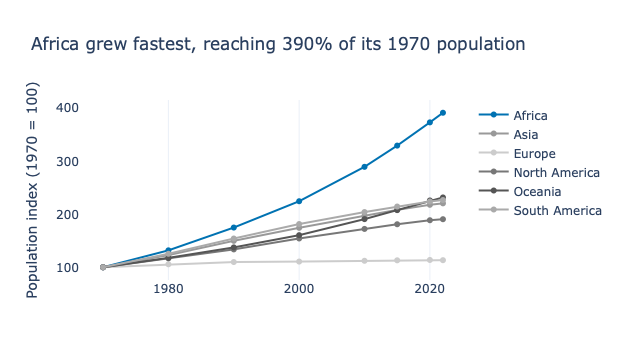

In [3]:
continent_year = (
    df_long.groupby(['Continent', 'Year'], as_index=False)
    ['Population'].sum()
)

base = continent_year[
    continent_year['Year'] == 1970
][['Continent', 'Population']].rename(
    columns={'Population': 'Base'}
)

continent_year = continent_year.merge(base, on='Continent')
continent_year['Growth Index'] = (
    continent_year['Population'] / continent_year['Base'] * 100
)

continent_year['Colour'] = np.where(
    continent_year['Continent'] == 'Africa',
    'Africa', 'Other continents'
)

fig = px.line(
    continent_year,
    x='Year',
    y='Growth Index',
    color='Continent',
    markers=True,
    color_discrete_map={
        'Africa': '#0072B2',
        'Asia': '#999999',
        'Europe': '#CCCCCC',
        'North America': '#777777',
        'South America': '#AAAAAA',
        'Oceania': '#555555'
    },
    title='Africa grew fastest, reaching 390% of its 1970 population',
    template='plotly_white'
)

fig.update_layout(
    xaxis_title=None,
    yaxis_title='Population index (1970 = 100)',
    legend_title=None,
    yaxis_showgrid=False
)

fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* A sorted horizontal bar chart makes it easy to compare population increases across 15 countries. African countries are highlighted in orange, while the others are grey. Four of the top 15 countries are in Africa.

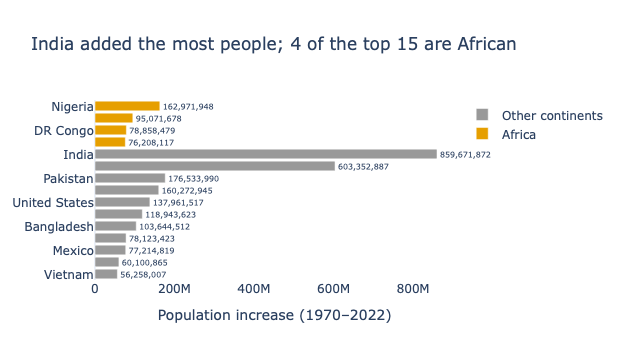

In [4]:
df['Population Added'] = (
    df['2022 Population'] - df['1970 Population']
)

top15 = df.nlargest(15, 'Population Added').copy()
top15 = top15.sort_values('Population Added')

top15['Group'] = np.where(
    top15['Continent'] == 'Africa',
    'Africa', 'Other continents'
)

africa_count = (top15['Continent'] == 'Africa').sum()

fig = px.bar(
    top15,
    x='Population Added',
    y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={
        'Africa': '#E69F00',
        'Other continents': '#999999'
    },
    title=f'India added the most people; {africa_count} of the top 15 are African',
    template='plotly_white',
    labels={'Population Added': 'People added'}
)

fig.update_traces(
    texttemplate='%{x:,.0f}',
    textposition='outside',
    cliponaxis=False
)

fig.update_layout(
    xaxis_title='Population increase (1970–2022)',
    yaxis_title=None,
    legend_title=None,
    xaxis_showgrid=False,
    margin=dict(r=125)
)

fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*A scatter plot shows the relationship between land area and population. Logarithmic scales help compare countries of very different sizes, while continent colours show regional patterns. The annotations highlight countries that demonstrate why land area alone cannot explain population.

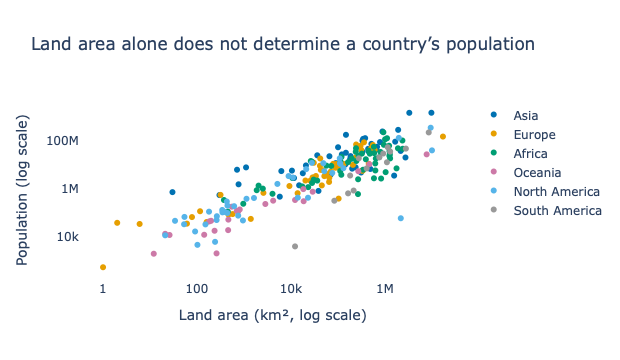

In [5]:
fig = px.scatter(
    df,
    x='Area',
    y='2022 Population',
    color='Continent',
    hover_name='Country',
    log_x=True,
    log_y=True,
    color_discrete_sequence=[
        '#0072B2', '#E69F00', '#009E73',
        '#CC79A7', '#56B4E9', '#999999'
    ],
    title='Land area alone does not determine a country’s population',
    template='plotly_white',
    labels={
        'Area': 'Land area (km², log scale)',
        '2022 Population': 'Population (log scale)'
    }
)

fig.update_layout(
    legend_title=None,
    xaxis_showgrid=False,
    yaxis_showgrid=False
)

for country in ['India', 'China', 'Russia', 'Bangladesh']:
    row = df[df['Country'] == country]
    if not row.empty:
        fig.add_annotation(
            x=row['Area'].iloc[0],
            y=row['2022 Population'].iloc[0],
            text=country,
            showarrow=True,
            arrowhead=2,
            ax=25,
            ay=-25
        )

fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* A box plot shows the median, spread and outliers of population density in each continent. The logarithmic scale makes it easier to compare countries with very different population densities.

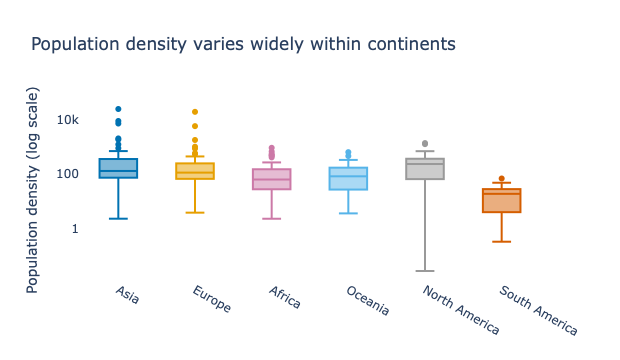

In [6]:
fig = px.box(
    df,
    x='Continent',
    y='Density',
    color='Continent',
    points='outliers',
    log_y=True,
    color_discrete_sequence=[
        '#0072B2', '#E69F00', '#CC79A7',
        '#56B4E9', '#999999', '#D55E00'
    ],
    title='Population density varies widely within continents',
    template='plotly_white',
    labels={'Density': 'People per km² (log scale)'}
)

fig.update_layout(
    xaxis_title=None,
    yaxis_title='Population density (log scale)',
    showlegend=False,
    yaxis_showgrid=False
)

fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*A choropleth map shows where population growth and decline occurred geographically. A diverging colour scale distinguishes countries with negative and positive population change

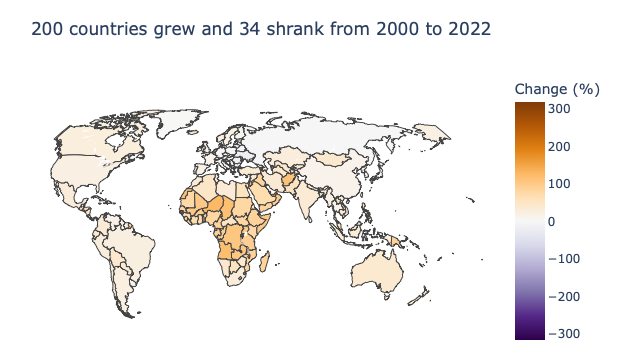

In [7]:
df['Population Change (%)'] = (
    (df['2022 Population'] - df['2000 Population'])
    / df['2000 Population'] * 100
)

shrinking = (df['Population Change (%)'] < 0).sum()
growing = (df['Population Change (%)'] > 0).sum()

fig = px.choropleth(
    df,
    locations='CCA3',
    locationmode='ISO-3',
    color='Population Change (%)',
    hover_name='Country',
    color_continuous_scale='PuOr_r',
    color_continuous_midpoint=0,
    title=f'{growing} countries grew and {shrinking} shrank from 2000 to 2022',
    template='plotly_white',
    labels={
        'Population Change (%)': 'Population change (%)'
    }
)

fig.update_geos(
    showcoastlines=False,
    showframe=False,
    projection_type='natural earth'
)

fig.update_layout(
    margin=dict(l=10, r=10, t=70, b=10),
    coloraxis_colorbar_title='Change (%)'
)

fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*A treemap displays the distribution of population using nested rectangles. The larger rectangles represent continents, and the smaller ones represent countries. Rectangle size corresponds to population, making the hierarchy easy to understand.

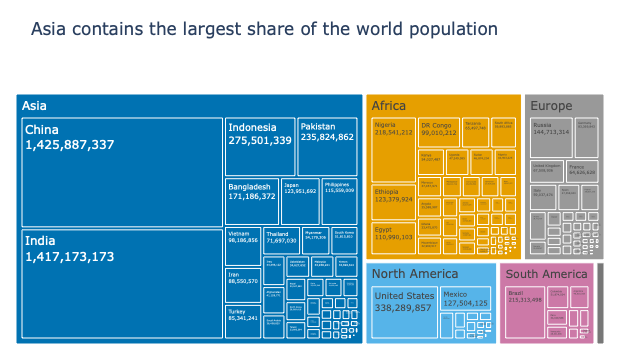

In [8]:
continent_total = (
    df.groupby('Continent')['2022 Population']
    .sum()
    .sort_values(ascending=False)
)

largest = continent_total.index[0]

fig = px.treemap(
    df,
    path=['Continent', 'Country'],
    values='2022 Population',
    color='Continent',
    color_discrete_map={
        'Asia': '#0072B2',
        'Africa': '#E69F00',
        'Europe': '#999999',
        'North America': '#56B4E9',
        'South America': '#CC79A7',
        'Oceania': '#777777'
    },
    title=f'Asia contains the largest share of the world population',
    template='plotly_white'
)

fig.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:,.0f}',
    hovertemplate='%{label}<br>Population: %{value:,.0f}<extra></extra>',
    root_color='white'
)

fig.update_layout(
    margin=dict(t=70, l=10, r=10, b=10)
)

fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* A 100% stacked bar chart is appropriate because it compares the relative population shares of different regions over time. Every bar totals 100%, allowing us to see how Africa, Asia, Europe and the rest of the world's proportions have changed.

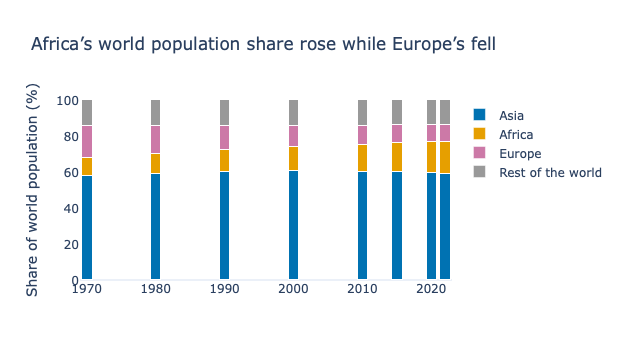

In [10]:
shares = (
    df_long.groupby(['Year', 'Continent'], as_index=False)
    ['Population'].sum()
)

shares['Group'] = shares['Continent'].where(
    shares['Continent'].isin(['Africa', 'Asia', 'Europe']),
    'Rest of the world'
)

shares = (
    shares.groupby(['Year', 'Group'], as_index=False)
    ['Population'].sum()
)

shares['World Total'] = (
    shares.groupby('Year')['Population'].transform('sum')
)

shares['Share (%)'] = (
    shares['Population'] / shares['World Total'] * 100
)

fig = px.bar(
    shares,
    x='Year',
    y='Share (%)',
    color='Group',
    barmode='stack',
    color_discrete_map={
        'Africa': '#E69F00',
        'Asia': '#0072B2',
        'Europe': '#CC79A7',
        'Rest of the world': '#999999'
    },
    title='Africa’s world population share rose while Europe’s fell',
    template='plotly_white',
    category_orders={
        'Group': [
            'Asia', 'Africa', 'Europe', 'Rest of the world'
        ]
    }
)

fig.update_layout(
    xaxis_title=None,
    yaxis_title='Share of world population (%)',
    yaxis_range=[0, 100],
    yaxis_showgrid=False,
    legend_title=None,
    bargap=0.25
)

fig.update_traces(
    hovertemplate='%{y:.1f}%<extra>%{fullData.name}</extra>'
)

fig.show()